# Machine Learning Lab - Assignment 08


**Name:** Abu Bakar Sadiq
### Program : AI "B" 
**Assignment:** Decision Trees | 
**Date:** Oct 20 2026



In [10]:
%pip install torch

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [1]:
%pip install scikit-learn matplotlib

error: externally-managed-environment

× This environment is externally managed
╰─> To install Python packages system-wide, try apt install
    python3-xyz, where xyz is the package you are trying to
    install.
    
    If you wish to install a non-Debian-packaged Python package,
    create a virtual environment using python3 -m venv path/to/venv.
    Then use path/to/venv/bin/python and path/to/venv/bin/pip. Make
    sure you have python3-full installed.
    
    If you wish to install a non-Debian packaged Python application,
    it may be easiest to use pipx install xyz, which will manage a
    virtual environment for you. Make sure you have pipx installed.
    
    See /usr/share/doc/python3.12/README.venv for more information.

note: If you believe this is a mistake, please contact your Python installation or OS distribution provider. You can override this, at the risk of breaking your Python installation or OS, by passing --break-system-packages.
hint: See PEP 668 for the detai

Note: you may need to restart the kernel to use updated packages.


In [12]:
import numpy as np
import sklearn as sk
import torch
print("NumPy:", np.__version__)
print("PyTorch:", torch.__version__)
print("Scikit-learn:", sk.__version__)

NumPy: 2.4.2
PyTorch: 2.14.1+cpu
Scikit-learn: 1.8.0


In [2]:
# Decision Tree using Information Gain (entropy)
import math
from collections import Counter
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree


### PART 1: entropy and information gain by hand

In [3]:
def entropy(labels):
    # entropy = -sum( p * log2(p) ) over every class
    total = len(labels)
    result = 0
    for count in Counter(labels).values():
        p = count / total          # proportion of this class
        result -= p * math.log2(p)
    return result

In [4]:
# AllElectronics data from the lecture: 9 "yes" and 5 "no"
start = entropy(["yes"] * 9 + ["no"] * 5)
print("Start entropy:", round(start, 4))              # should print 0.9403

# splitting on age gives three groups: <30 (2 yes, 3 no),
# 30..40 (4 yes, 0 no), >40 (3 yes, 2 no)
groups = [["yes"] * 2 + ["no"] * 3,
          ["yes"] * 4,
          ["yes"] * 3 + ["no"] * 2]

weighted = sum(len(g) / 14 * entropy(g) for g in groups)   # weighted entropy
print("Information gain of age:", round(start - weighted, 4))  # 0.2467

Start entropy: 0.9403
Information gain of age: 0.2467


### PART 2: train a decision tree on real data

In [5]:
TEST_SIZE = 0.3    # fraction of data kept aside for testing
MAX_DEPTH = 3      # how deep the tree is allowed to grow
SEED = 1           # changes which rows go to train / test

data = load_iris()
X_train, X_test, y_train, y_test = train_test_split(
    data.data, data.target, test_size=TEST_SIZE, random_state=SEED)

# criterion="entropy" means every split is chosen by information gain
model = DecisionTreeClassifier(criterion="entropy", max_depth=MAX_DEPTH,
                               random_state=SEED)
model.fit(X_train, y_train)    # training happens here

,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'entropy'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",3
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary ` for details.",1
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current 

### PART 3: accuracy and errors

In [6]:
train_acc = model.score(X_train, y_train)               # accuracy on data it has seen
test_acc = model.score(X_test, y_test)                  # accuracy on unseen data
wrong = (model.predict(X_test) != y_test).sum()         # number of wrong predictions

print("Train accuracy:", round(train_acc, 3))
print("Test accuracy :", round(test_acc, 3))
print("Wrong predictions:", wrong, "out of", len(y_test))

Train accuracy: 0.981
Test accuracy : 0.956
Wrong predictions: 2 out of 45


### PART 4: visuals

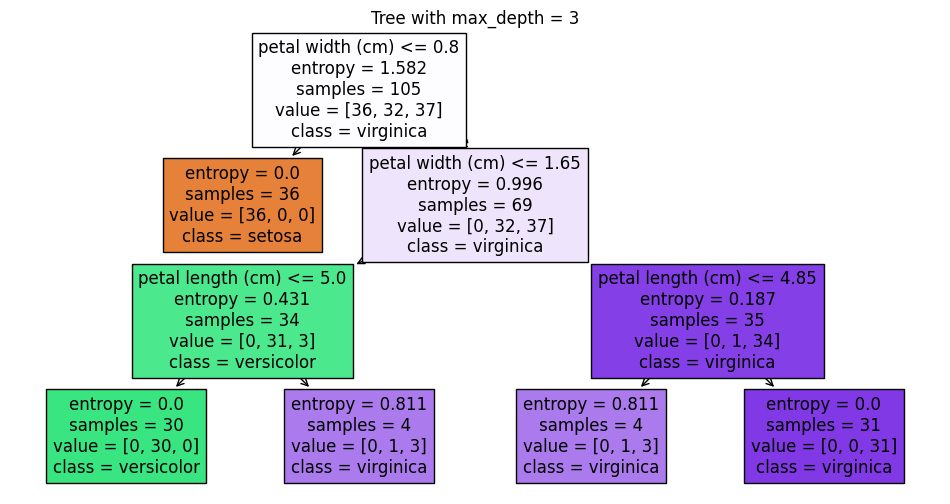

In [7]:
# picture 1: the tree that was learned
plt.figure(figsize=(12, 6))
plot_tree(model, feature_names=data.feature_names,
          class_names=data.target_names, filled=True)
plt.title("Tree with max_depth = " + str(MAX_DEPTH))
plt.show()

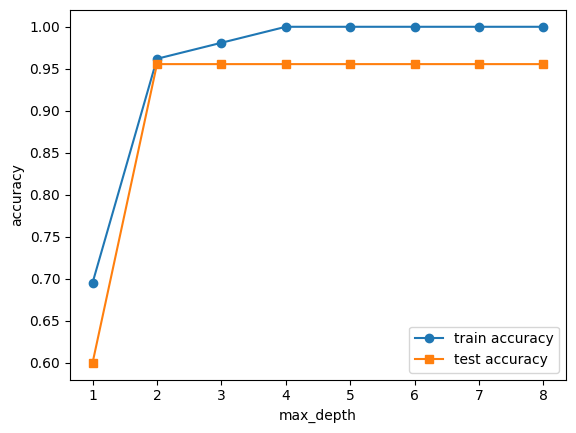

In [8]:
# picture 2: accuracy for every depth from 1 to 8

depths = range(1, 9)
train_list, test_list = [], []
for d in depths:
    m = DecisionTreeClassifier(criterion="entropy", max_depth=d,
                               random_state=SEED).fit(X_train, y_train)
    train_list.append(m.score(X_train, y_train))
    test_list.append(m.score(X_test, y_test))

plt.figure()
plt.plot(depths, train_list, marker="o", label="train accuracy")
plt.plot(depths, test_list, marker="s", label="test accuracy")
plt.xlabel("max_depth")
plt.ylabel("accuracy")
plt.legend()
plt.show()

### PART A: Change one value at a time
Har run mein sirf ek setting change hui hai, baqi do original (TEST_SIZE=0.3, MAX_DEPTH=3, SEED=1) par hain.

In [9]:
# helper: ek run karta hai aur results return karta hai
def run_once(test_size, max_depth, seed, criterion="entropy"):
    Xtr, Xte, ytr, yte = train_test_split(
        data.data, data.target, test_size=test_size, random_state=seed)
    mdl = DecisionTreeClassifier(criterion=criterion, max_depth=max_depth,
                                 random_state=seed)
    mdl.fit(Xtr, ytr)
    tr = mdl.score(Xtr, ytr)
    te = mdl.score(Xte, yte)
    wr = (mdl.predict(Xte) != yte).sum()
    return mdl, tr, te, wr, len(yte)

In [10]:
# (TEST_SIZE, MAX_DEPTH, SEED) for runs 1 to 8
runs = [(0.3, 3, 1), (0.3, 1, 1), (0.3, 2, 1), (0.3, 8, 1),
        (0.5, 3, 1), (0.1, 3, 1), (0.3, 3, 7), (0.3, 3, 42)]

print("Run  TEST_SIZE  MAX_DEPTH  SEED  Train_acc  Test_acc  Wrong")
for i, (ts, md_, sd) in enumerate(runs, start=1):
    mdl, tr, te, wr, n = run_once(ts, md_, sd)
    print(f"{i:<4} {ts:<10} {md_:<10} {sd:<5} {tr:<10.3f} {te:<9.3f} {wr} out of {n}")

Run  TEST_SIZE  MAX_DEPTH  SEED  Train_acc  Test_acc  Wrong
1    0.3        3          1     0.981      0.956     2 out of 45
2    0.3        1          1     0.695      0.600     18 out of 45
3    0.3        2          1     0.962      0.956     2 out of 45
4    0.3        8          1     1.000      0.956     2 out of 45
5    0.5        3          1     0.973      0.973     2 out of 75
6    0.1        3          1     0.970      1.000     0 out of 15
7    0.3        3          7     0.981      0.889     5 out of 45
8    0.3        3          42    0.952      0.978     1 out of 45


#### Tree pictures for runs 1, 2 and 4

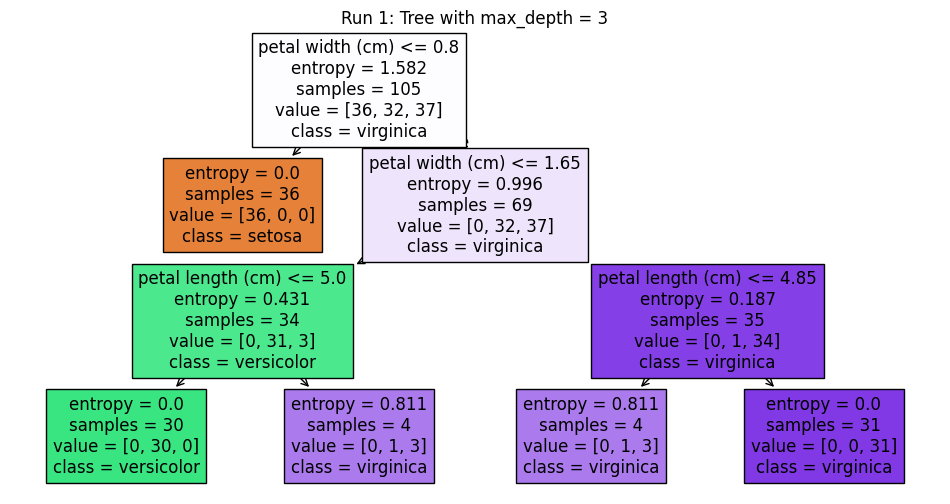

In [11]:
# Run 1: MAX_DEPTH = 3
mdl, tr, te, wr, n = run_once(0.3, 3, 1)
plt.figure(figsize=(12, 6))
plot_tree(mdl, feature_names=data.feature_names,
          class_names=data.target_names, filled=True)
plt.title("Run 1: Tree with max_depth = 3")
plt.show()

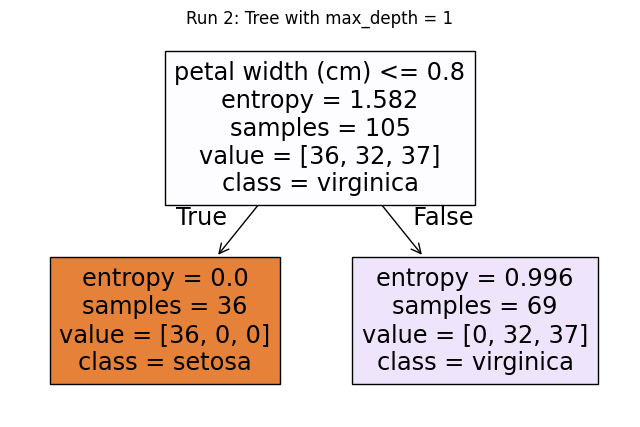

In [12]:
# Run 2: MAX_DEPTH = 1
mdl, tr, te, wr, n = run_once(0.3, 1, 1)
plt.figure(figsize=(8, 5))
plot_tree(mdl, feature_names=data.feature_names,
          class_names=data.target_names, filled=True)
plt.title("Run 2: Tree with max_depth = 1")
plt.show()

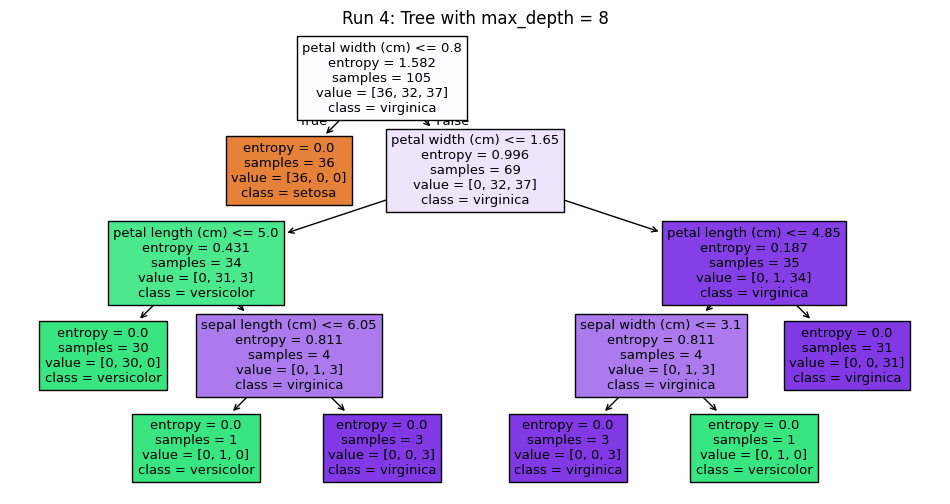

In [13]:
# Run 4: MAX_DEPTH = 8
mdl, tr, te, wr, n = run_once(0.3, 8, 1)
plt.figure(figsize=(12, 6))
plot_tree(mdl, feature_names=data.feature_names,
          class_names=data.target_names, filled=True)
plt.title("Run 4: Tree with max_depth = 8")
plt.show()

#### Question 7: criterion = "gini" (original settings)

entropy -> train: 0.981 test: 0.956 wrong: 2 out of 45
gini -> train: 0.981 test: 0.956 wrong: 2 out of 45


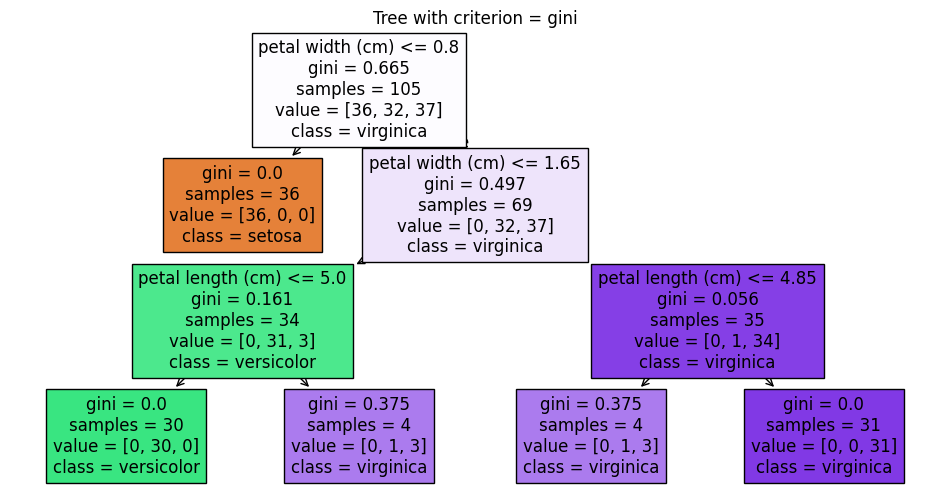

In [14]:
for crit in ["entropy", "gini"]:
    mdl, tr, te, wr, n = run_once(0.3, 3, 1, criterion=crit)
    print(crit, "-> train:", round(tr, 3), "test:", round(te, 3),
          "wrong:", wr, "out of", n)

plt.figure(figsize=(12, 6))
plot_tree(mdl, feature_names=data.feature_names,
          class_names=data.target_names, filled=True)
plt.title("Tree with criterion = gini")
plt.show()

### PART C: Entropy by hand

In [15]:
print(entropy(["yes"] * 4))                  # pure group
print(entropy(["yes"] * 4 + ["no"] * 4))     # perfectly mixed group

0.0
1.0


In [16]:
print(entropy(["yes"] * 4))                  # pure group
print(entropy(["yes"] * 7 + ["no"] * 1))     # 7 yes, 1 no

0.0
0.5435644431995964
